In [2]:
# we'll want to plot our loss for all 3 phases, (both train and test)

import glob
import pandas as pd
import matplotlib.pyplot as plt

def load(phase):
    d = sorted(glob.glob(f"phase_{phase}_logs.nosync/*"))[-1]
    return pd.read_csv(f"{d}/train.csv"), pd.read_csv(f"{d}/test.csv")

def plot_phase(phase, title, window=50, logy=False):
    tr, te = load(phase)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(tr.step, tr.loss, alpha=0.2, lw=0.8, label="train (last micro-batch)")
    ax.plot(tr.step, tr.loss.rolling(window, min_periods=1).mean(), lw=2, label=f"train (rolling {window})")
    ax.plot(te.step, te.loss, "o-", lw=2, label="test")
    if logy:
        ax.set_yscale("log")
    ax.set(xlabel="optimizer step (256 rows)", ylabel="cross-entropy (nats / token)", title=title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

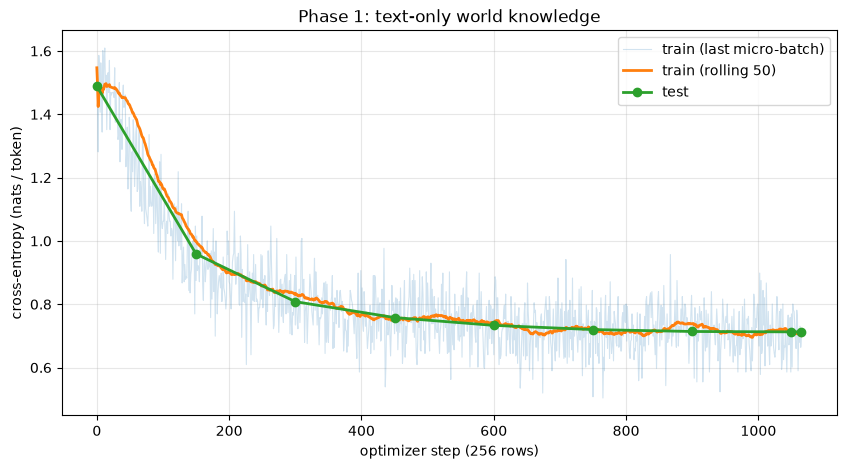

In [3]:
# phase 1 
plot_phase("one", "Phase 1: text-only world knowledge")

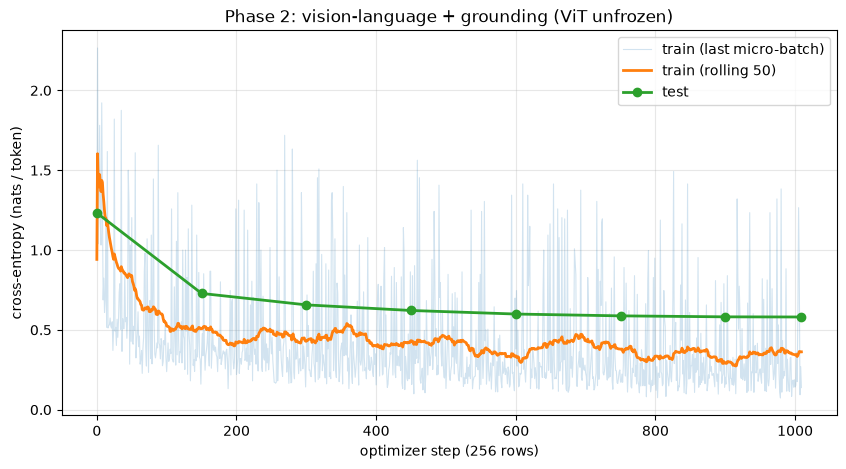

In [4]:
# phase 2
plot_phase("two", "Phase 2: vision-language + grounding (ViT unfrozen)")

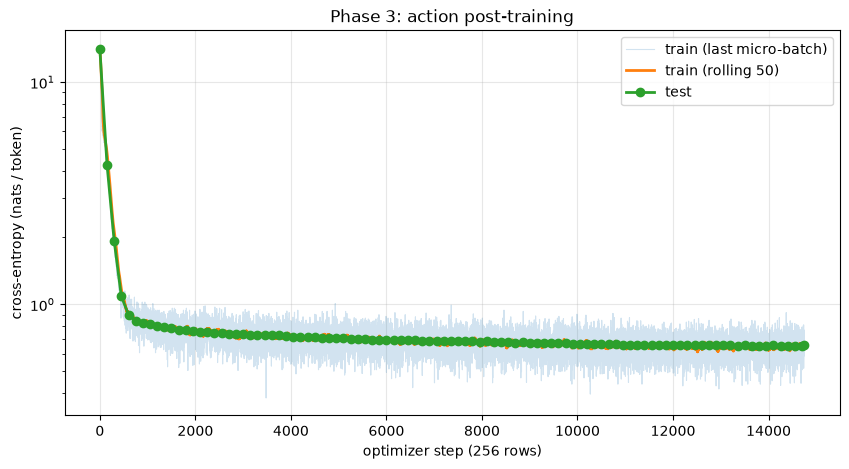

In [5]:
# phase 3 
plot_phase("three", "Phase 3: action post-training", logy=True)

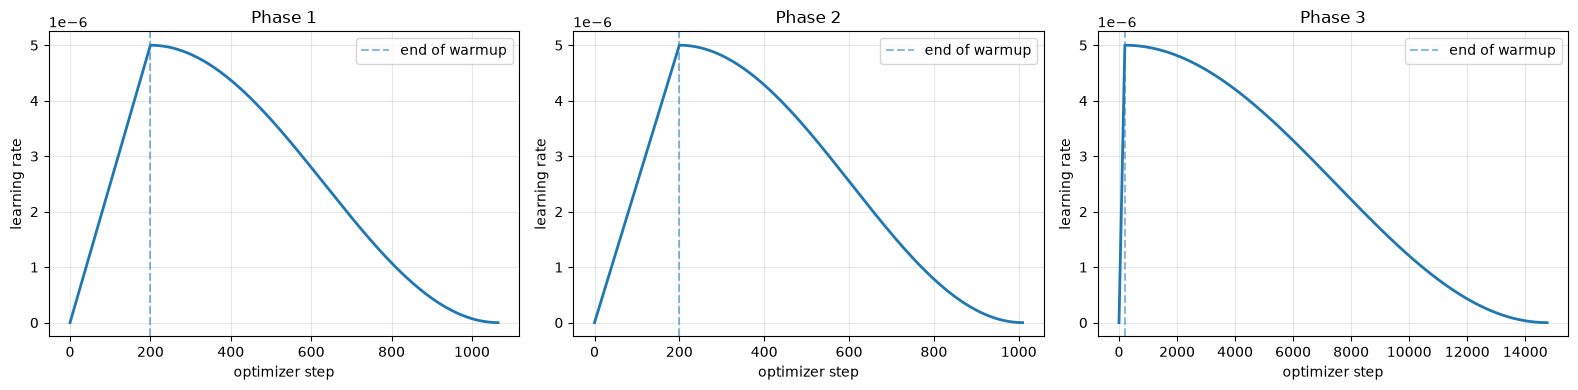

In [ ]:
# learning rate for our 3 phases

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (phase, title) in zip(axes, [("one", "Phase 1"), ("two", "Phase 2"), ("three", "Phase 3")]):
    tr, _ = load(phase)
    ax.plot(tr.step, tr.lr, lw=2)
    ax.axvline(200, ls="--", alpha=0.5, label="end of warmup")
    ax.set(xlabel="optimizer step", ylabel="learning rate", title=title)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
# all cosine, as expected